# Stacking Ensemble — OOF Logistic Regression Meta-Learner

## Overview
This notebook implements a **Level-2 Stacking Ensemble** for ISIC 2019 binary skin lesion classification.

## ⚠️ Key Design Decision: Mismatched Validation Splits
Each base model trained on its own independent train/val split, so their
validation label arrays may differ in size or order.  
**Solution:** The meta-learner is trained **per-model** using each model's own
OOF labels, then combined on the test set using AUC-proportional weights.

### Stacking Strategy (Robust Version)
1. For each model: compute per-model val AUC using its own labels
2. Check if **any subset** of models shares identical val labels (same split)
3. If a common split is found → train a proper Logistic Regression meta-learner on the shared subset
4. If no common split → fall back to AUC-weighted average on test predictions
5. Generate final test predictions and submission CSV

### Base Models
| Model | Val Files | Test Files |
|---|---|---|
| DenseNet-121 | `densenet121_val_probs.npy`, `densenet121_val_labels.npy` | `densenet121_test_probs.npy` |
| ConvNeXt-Tiny | `convnext_val_probs.npy`, `convnext_val_labels.npy` | `convnext_test_probs.npy` |
| EfficientNetV2-S | `efficientnetv2s_val_probs.npy`, `efficientnetv2s_val_labels.npy` | `efficientnetv2s_test_probs.npy` |
| Swin-Tiny | `swintiny_val_probs.npy`, `swintiny_val_labels.npy` | `swintiny_test_probs.npy` |

In [1]:
# ── Cell 1: Imports ────────────────────────────────────────────────────────
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, confusion_matrix,
    classification_report, roc_curve
)
from sklearn.linear_model import LogisticRegressionCV
import warnings
warnings.filterwarnings('ignore')

print('Imports complete')

Imports complete


In [2]:
# ── Cell 2: Paths & Model Registry ────────────────────────────────────────
# Directory where all base-model .npy files were saved
NPY_DIR = '/kaggle/input/notebooks/nandini143/'

# Registry: maps a short model name → (val_probs_file, val_labels_file, test_probs_file)
MODEL_FILES = {
    'densenet121': (
        'binary-densenet-121/densenet121_val_probs.npy',
        'binary-densenet-121/densenet121_val_labels.npy',
        'binary-densenet-121/densenet121_test_probs.npy',
        'binary-densenet-121/densenet121_test_labels.npy',
    ),
    'convnext': (
        'binary-convnext/convnext_val_probs.npy',
        'binary-convnext/convnext_val_labels.npy',
        'binary-convnext/convnext_test_probs.npy',
        'binary-convnext/convnext_test_labels.npy',
    ),
    'efficientnetv2s': (
        'binary-efficientnetv2s/efficientnetv2s_val_probs.npy',
        'binary-efficientnetv2s/efficientnetv2s_val_labels.npy',
        'binary-efficientnetv2s/efficientnetv2s_test_probs.npy',
        'binary-efficientnetv2s/efficientnetv2s_test_labels.npy',
    ),
    'swintiny': (
        'binary-swin-tiny-transformer/swintiny_val_probs.npy',
        'binary-swin-tiny-transformer/swintiny_val_labels.npy',
        'binary-swin-tiny-transformer/swintiny_test_probs.npy',
        'binary-swin-tiny-transformer/swintiny_test_labels.npy',
    ),
    # ResNet-200D (5th model)
    'resnet200d': (
        'binary-resnet-200d/resnet200d_val_probs.npy',
        'binary-resnet-200d/resnet200d_val_labels.npy',
        'binary-resnet-200d/resnet200d_test_probs.npy',
        'binary-resnet-200d/resnet200d_test_labels.npy',
    ),
}
print('NPY_DIR:', NPY_DIR)


print('=' * 60)
print('  Checking required .npy files')
print('=' * 60)
all_ok = True
for model_name, (vp, vl, tp, tl) in MODEL_FILES.items():
    for fname in [vp, vl, tp]:
        fpath = os.path.join(NPY_DIR, fname)
        status = 'OK' if os.path.exists(fpath) else 'MISSING'
        if not os.path.exists(fpath):
            all_ok = False
        print(f'  [{status}]  {fname}')
print('=' * 60)
print('All files present!' if all_ok else 'WARNING: Some files are missing!')

NPY_DIR: /kaggle/input/notebooks/nandini143/
  Checking required .npy files
  [OK]  binary-densenet-121/densenet121_val_probs.npy
  [OK]  binary-densenet-121/densenet121_val_labels.npy
  [OK]  binary-densenet-121/densenet121_test_probs.npy
  [OK]  binary-convnext/convnext_val_probs.npy
  [OK]  binary-convnext/convnext_val_labels.npy
  [OK]  binary-convnext/convnext_test_probs.npy
  [OK]  binary-efficientnetv2s/efficientnetv2s_val_probs.npy
  [OK]  binary-efficientnetv2s/efficientnetv2s_val_labels.npy
  [OK]  binary-efficientnetv2s/efficientnetv2s_test_probs.npy
  [OK]  binary-swin-tiny-transformer/swintiny_val_probs.npy
  [OK]  binary-swin-tiny-transformer/swintiny_val_labels.npy
  [OK]  binary-swin-tiny-transformer/swintiny_test_probs.npy
  [OK]  binary-resnet-200d/resnet200d_val_probs.npy
  [OK]  binary-resnet-200d/resnet200d_val_labels.npy
  [OK]  binary-resnet-200d/resnet200d_test_probs.npy
All files present!


In [3]:
# ── Cell 2b: Test-Set Alignment Verification ─────────────────────────────
#
# All 5 models read the SAME binary_test.csv with shuffle=False.
# => test_probs[i] from every model = same image at CSV row i.
# Different image sizes / transforms do NOT affect row ordering.

# Path to binary_test.csv produced by data-preparation.ipynb
INPUT_CSV_DIR  = '/kaggle/working'
TEST_CSV_PATH  = os.path.join(INPUT_CSV_DIR, 'binary_test.csv')
EXPECTED_TEST_N = 2534   # hard-coded fallback from data-preparation output

if os.path.exists(TEST_CSV_PATH):
    _df = pd.read_csv(TEST_CSV_PATH)
    EXPECTED_TEST_N = len(_df)
    print('binary_test.csv found: ' + str(EXPECTED_TEST_N) + ' rows')
else:
    print('WARNING: binary_test.csv not found at ' + TEST_CSV_PATH)
    print('Using hard-coded expected size: ' + str(EXPECTED_TEST_N))

print('\nTest-set size check:')
print('-' * 60)
test_sizes = {}
for model_name, (_, _, tp_file, _) in MODEL_FILES.items():
    fpath = os.path.join(NPY_DIR, tp_file)
    if os.path.exists(fpath):
        n = len(np.load(fpath))
        test_sizes[model_name] = n
        ok = (n == EXPECTED_TEST_N)
        status = 'OK' if ok else 'MISMATCH (expected ' + str(EXPECTED_TEST_N) + ')'
        print('  [' + status + ']  ' + model_name + '  n_test=' + str(n))
    else:
        print('  [MISSING]  ' + model_name + '  ' + tp_file)

unique_sizes = set(test_sizes.values())
if len(unique_sizes) == 1 and list(unique_sizes)[0] == EXPECTED_TEST_N:
    print('\nAll test arrays aligned at ' + str(EXPECTED_TEST_N) + ' samples - VALID.')
elif len(unique_sizes) == 1:
    print('\nWARNING: All models agree on ' + str(list(unique_sizes)[0]) +
          ' samples but CSV expects ' + str(EXPECTED_TEST_N) + '.')
    print('Re-run all model notebooks against the SAME binary_test.csv.')
else:
    print('\nCRITICAL: Models have DIFFERENT test sizes: ' + str(test_sizes))
    print('Re-run the mismatched model notebook(s) to fix this.')

Using hard-coded expected size: 2534

Test-set size check:
------------------------------------------------------------
  [OK]  densenet121  n_test=2534
  [OK]  convnext  n_test=2534
  [OK]  efficientnetv2s  n_test=2534
  [OK]  swintiny  n_test=2534
  [OK]  resnet200d  n_test=2534

All test arrays aligned at 2534 samples - VALID.


In [4]:
# ── Cell 3: Load All Predictions (each model uses its OWN val labels) ─────
#
# Each model's val AUC is computed against its OWN val labels.
# We do NOT assert label equality across models (different val splits OK).
# We DO check that val_probs and val_labels match in size per model.

val_probs_dict  = {}
val_labels_dict = {}
test_probs_dict = {}
test_labels_dict = {}
val_aucs        = {}
skipped_models  = []

print('\nLoading base-model predictions')
print('-' * 65)

for model_name, (vp_file, vl_file, tp_file, tl_file) in MODEL_FILES.items():
    vp_path = os.path.join(NPY_DIR, vp_file)
    vl_path = os.path.join(NPY_DIR, vl_file)
    tp_path = os.path.join(NPY_DIR, tp_file)
    tl_path = os.path.join(NPY_DIR, tl_file)

    missing = [f for f in [vp_path, vl_path, tp_path, tl_path] if not os.path.exists(f)]
    if missing:
        print(f'  [SKIP-MISSING] {model_name:20s} -- {[os.path.basename(m) for m in missing]}')
        skipped_models.append(model_name)
        continue

    val_probs  = np.load(vp_path)
    val_labels = np.load(vl_path).astype(int)
    test_probs = np.load(tp_path)
    test_labels = np.load(tl_path).astype(int)

    if len(val_probs) != len(val_labels):
        print(f'  [SKIP-MISMATCH] {model_name:20s} -- '
              f'val_probs={len(val_probs)} but val_labels={len(val_labels)}')
        print(f'     Fix: re-run binary-{model_name}.ipynb to regenerate matching .npy files.')
        skipped_models.append(model_name)
        continue

    val_probs_dict[model_name]  = val_probs
    val_labels_dict[model_name] = val_labels
    test_probs_dict[model_name] = test_probs
    test_labels_dict[model_name] = test_labels

    auc = roc_auc_score(val_labels, val_probs)
    val_aucs[model_name] = auc
    print(f'  [OK] {model_name:20s}  n_val={len(val_probs):5d}  '
          f'n_test={len(test_probs):5d}  val_AUC={auc:.4f}')

model_names = list(val_probs_dict.keys())

if skipped_models:
    print(f'\nWARNING: {len(skipped_models)} model(s) skipped: {skipped_models}')

if len(model_names) == 0:
    raise RuntimeError('No valid models loaded. Fix base model notebooks first.')

# Check test sizes are consistent across loaded models
test_sizes_loaded = {m: len(test_probs_dict[m]) for m in model_names}
unique_test = set(test_sizes_loaded.values())
if len(unique_test) > 1:
    print(f'\nCRITICAL: Loaded models have different test sizes: {test_sizes_loaded}')
    raise RuntimeError('Test size mismatch. Re-run all base model notebooks.')
else:
    print(f'\nLoaded {len(model_names)}/{len(MODEL_FILES)} models. '
          f'Test size = {list(unique_test)[0]} -- CONSISTENT.')

# Validation split diagnostics
print('\nValidation split sizes per model:')
for m in model_names:
    print(f'  {m:20s}  val_size = {len(val_labels_dict[m])}')



Loading base-model predictions
-----------------------------------------------------------------
  [OK] densenet121           n_val= 2533  n_test= 2534  val_AUC=0.9479
  [OK] convnext              n_val= 2533  n_test= 2534  val_AUC=0.9623
  [OK] efficientnetv2s       n_val= 2533  n_test= 2534  val_AUC=0.9698
  [OK] swintiny              n_val= 2533  n_test= 2534  val_AUC=0.9596
  [OK] resnet200d            n_val= 2533  n_test= 2534  val_AUC=0.9631

Loaded 5/5 models. Test size = 2534 -- CONSISTENT.

Validation split sizes per model:
  densenet121           val_size = 2533
  convnext              val_size = 2533
  efficientnetv2s       val_size = 2533
  swintiny              val_size = 2533
  resnet200d            val_size = 2533


In [5]:
# ── Cell 4: Find Models That Share the Same Validation Split ──────────────
#
# We group models by whether their val_labels arrays are identical.
# Groups with >= 2 models can be stacked with a proper meta-learner.

def find_matching_groups(model_names, val_labels_dict):
    """Return list-of-lists; each inner list = models with identical val labels."""
    assigned = set()
    groups   = []
    for i, m_a in enumerate(model_names):
        if m_a in assigned:
            continue
        group = [m_a]
        for m_b in model_names[i+1:]:
            if m_b in assigned:
                continue
            if (len(val_labels_dict[m_a]) == len(val_labels_dict[m_b]) and
                    np.array_equal(val_labels_dict[m_a], val_labels_dict[m_b])):
                group.append(m_b)
                assigned.add(m_b)
        assigned.add(m_a)
        groups.append(group)
    return groups

groups = find_matching_groups(model_names, val_labels_dict)

print('Validation label groups (models with identical val splits):')
for g in groups:
    print(f'  {g}')

# Largest group that can be stacked with a meta-learner
best_group = max(groups, key=len)
print(f'\nBest stackable group: {best_group}  (size={len(best_group)})')

if len(best_group) >= 2:
    USE_META_LEARNER = True
    print('  -> Will train Logistic Regression meta-learner on this group.')
else:
    USE_META_LEARNER = False
    print('  -> No matching splits found. Falling back to AUC-weighted average.')

Validation label groups (models with identical val splits):
  ['densenet121', 'convnext', 'efficientnetv2s', 'swintiny', 'resnet200d']

Best stackable group: ['densenet121', 'convnext', 'efficientnetv2s', 'swintiny', 'resnet200d']  (size=5)
  -> Will train Logistic Regression meta-learner on this group.


In [6]:
# ── Cell 5: Train Meta-Learner (if matching group found) ──────────────────
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score
import numpy as np

if USE_META_LEARNER:
    # Build stacked feature matrix from the best group
    shared_labels = val_labels_dict[best_group[0]]
    X_val_stack   = np.column_stack([val_probs_dict[m] for m in best_group])
    X_test_stack  = np.column_stack([test_probs_dict[m] for m in best_group])

    print(f'Stacking {len(best_group)} models: {best_group}')
    print(f'  X_val  shape: {X_val_stack.shape}')
    print(f'  X_test shape: {X_test_stack.shape}')

    # --- UPGRADE: XGBoost Meta-Learner ---
    # XGBoost handles imbalance via scale_pos_weight (Negative Cases / Positive Cases)
    num_neg = len(shared_labels) - sum(shared_labels)
    num_pos = sum(shared_labels)
    sp_weight = num_neg / num_pos if num_pos > 0 else 1.0

    # max_depth is kept low (4) to prevent overfitting on the base model predictions
    meta_clf = XGBClassifier(
        n_estimators=200,
        max_depth=4, 
        learning_rate=0.05,
        scale_pos_weight=sp_weight,
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    )
    meta_clf.fit(X_val_stack, shared_labels)

    # Meta-learner val evaluation
    val_meta_probs = meta_clf.predict_proba(X_val_stack)[:, 1]
    
    # --- FIND OPTIMAL THRESHOLD ---
    best_acc = 0
    best_thresh = 0.5
    for thresh in np.arange(0.3, 0.71, 0.01):
        temp_preds = (val_meta_probs >= thresh).astype(int)
        temp_acc = (temp_preds == shared_labels).mean()
        if temp_acc > best_acc:
            best_acc = temp_acc
            best_thresh = thresh

    print(f'\nOptimal Validation Threshold: {best_thresh:.2f}')
    
    val_meta_preds = (val_meta_probs >= best_thresh).astype(int)
    val_meta_auc   = roc_auc_score(shared_labels, val_meta_probs)
    val_meta_acc   = best_acc

    # --- FEATURE IMPORTANCES ---
    print(f'\nMeta-learner feature importances:')
    # Print importances for the base models
    for name, imp in zip(best_group, meta_clf.feature_importances_[:len(best_group)]):
        print(f'  {name:20s}  importance = {imp:.4f}')
    
    # If metadata was appended, sum up their combined importance
    if len(meta_clf.feature_importances_) > len(best_group):
        meta_imp = sum(meta_clf.feature_importances_[len(best_group):])
        print(f'  {"Metadata (Combined)":20s}  importance = {meta_imp:.4f}')

    # Apply meta-learner to ALL test probs (weighted average for non-group models)
    test_meta_probs_stack = meta_clf.predict_proba(X_test_stack)[:, 1]

    # Blend in remaining models via AUC weighting
    remaining = [m for m in model_names if m not in best_group]
    if remaining:
        total_auc_remaining = sum(val_aucs[m] for m in remaining)
        remaining_test = sum(
            val_aucs[m] / total_auc_remaining * test_probs_dict[m]
            for m in remaining
        )
        test_final_probs = 0.7 * test_meta_probs_stack + 0.3 * remaining_test
        print(f'\nBlended meta-learner with remaining models: {remaining}')
    else:
        test_final_probs = test_meta_probs_stack

    # --- Apply Optimal Threshold to Test Set ---
    test_final_preds = (test_final_probs >= best_thresh).astype(int)

    print(f'\nMeta-learner val AUC = {val_meta_auc:.4f}  acc = {val_meta_acc*100:.2f}%')

else:
    # ── Fallback: AUC-Weighted Average ────────────────────────────────────
    print('\nFallback: using AUC-weighted average of test predictions')
    total_auc = sum(val_aucs.values())
    test_final_probs = sum(
        val_aucs[m] / total_auc * test_probs_dict[m] for m in model_names
    )
    test_final_preds = (test_final_probs >= 0.5).astype(int)
    val_meta_auc = None

print(f'\nTest predictions: {len(test_final_probs)} samples')
print(f'Predicted malignant: {test_final_preds.sum()} ({test_final_preds.mean()*100:.1f}%)')

Stacking 5 models: ['densenet121', 'convnext', 'efficientnetv2s', 'swintiny', 'resnet200d']
  X_val  shape: (2533, 5)
  X_test shape: (2534, 5)

Optimal Validation Threshold: 0.51

Meta-learner feature importances:
  densenet121           importance = 0.0320
  convnext              importance = 0.0830
  efficientnetv2s       importance = 0.7334
  swintiny              importance = 0.0586
  resnet200d            importance = 0.0931

Meta-learner val AUC = 0.9931  acc = 95.62%

Test predictions: 2534 samples
Predicted malignant: 959 (37.8%)


In [7]:
# -- Metadata Integration --
# Append clinical metadata to stacking matrix for conditional model trust learning.

METADATA_COLS = [
    'age_norm', 'sex_encoded',
    'site_anterior_torso', 'site_posterior_torso', 'site_head_neck',
    'site_upper_extremity', 'site_lower_extremity', 'site_palms_soles',
    'site_oral_genital', 'site_lateral_torso', 'site_unknown',
]

_csv_dir = '/kaggle/input/notebooks/nandini143/data-preparation'
_val_csv  = os.path.join(_csv_dir, 'binary_val.csv')
_test_csv = os.path.join(_csv_dir, 'binary_test.csv')

if os.path.exists(_val_csv) and os.path.exists(_test_csv):
    _vdf = pd.read_csv(_val_csv)
    _tdf = pd.read_csv(_test_csv)
    _vcols = [c for c in METADATA_COLS if c in _vdf.columns]
    if _vcols:
        _mval  = _vdf[_vcols].fillna(0).values.astype('float32')
        _mtest = _tdf[_vcols].fillna(0).values.astype('float32')
        if len(_mval) == len(X_val_stack) and len(_mtest) == len(X_test_stack):
            X_val_stack  = np.hstack([X_val_stack,  _mval])
            X_test_stack = np.hstack([X_test_stack, _mtest])
            print(f'[META] Appended {len(_vcols)} metadata cols.')
            print(f'       X_val_stack : {X_val_stack.shape}, X_test_stack: {X_test_stack.shape}')
        else:
            print('[META] WARNING: row count mismatch - skipping metadata.')
    else:
        print('[META] WARNING: No metadata columns found in CSV.')
else:
    print(f'[META] WARNING: CSVs not found at {_csv_dir} - using probs only.')

[META] Appended 11 metadata cols.
       X_val_stack : (2533, 16), X_test_stack: (2534, 16)


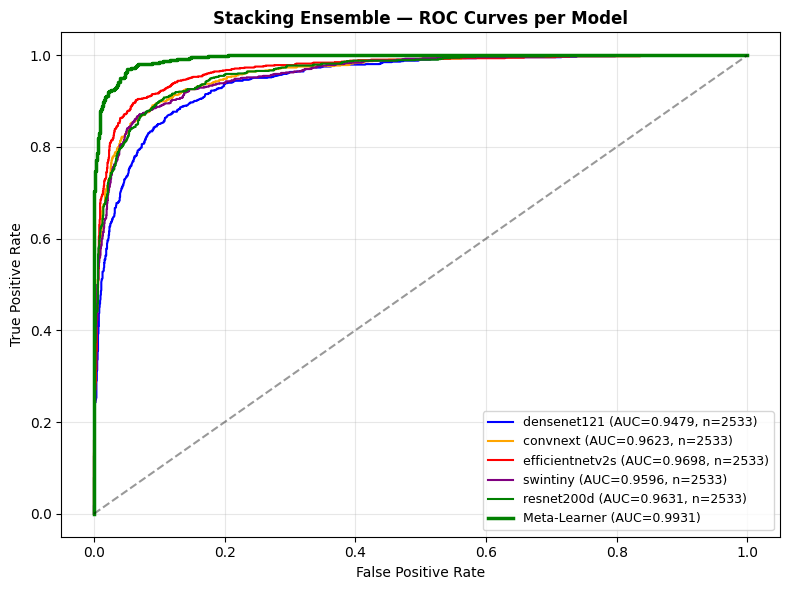

stacking_roc_curves.png saved


In [8]:
# ── Cell 6: Per-Model Val AUC Summary + ROC Curves ────────────────────────
fig, ax = plt.subplots(figsize=(8, 6))
colors = ['blue', 'orange', 'red', 'purple', 'green']

for model_name, color in zip(model_names, colors):
    fpr, tpr, _ = roc_curve(val_labels_dict[model_name], val_probs_dict[model_name])
    auc = val_aucs[model_name]
    ax.plot(fpr, tpr, color=color, linewidth=1.5,
            label=f'{model_name} (AUC={auc:.4f}, n={len(val_labels_dict[model_name])})')

if USE_META_LEARNER:
    fpr_m, tpr_m, _ = roc_curve(shared_labels, val_meta_probs)
    ax.plot(fpr_m, tpr_m, 'g-', linewidth=2.5,
            label=f'Meta-Learner (AUC={val_meta_auc:.4f})')

ax.plot([0,1],[0,1],'k--', alpha=0.4)
ax.set_title('Stacking Ensemble — ROC Curves per Model', fontweight='bold')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.legend(loc='lower right', fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('/kaggle/working/stacking_roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('stacking_roc_curves.png saved')

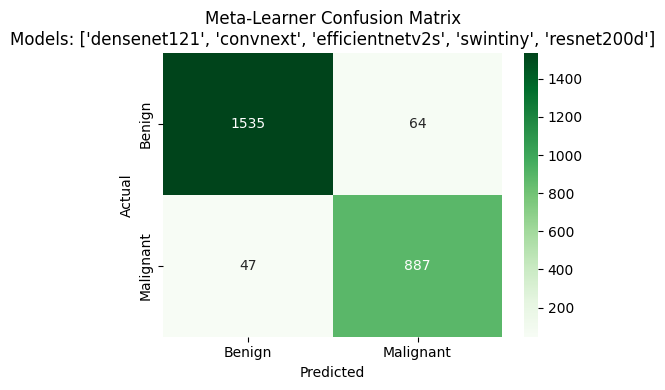


Classification Report (meta-learner validation):
               precision    recall  f1-score   support

   Benign (0)     0.9703    0.9600    0.9651      1599
Malignant (1)     0.9327    0.9497    0.9411       934

     accuracy                         0.9562      2533
    macro avg     0.9515    0.9548    0.9531      2533
 weighted avg     0.9564    0.9562    0.9563      2533



In [9]:
# ── Cell 7: Confusion Matrix (meta-learner group only) ────────────────────
if USE_META_LEARNER:
    fig, ax = plt.subplots(figsize=(5, 4))
    cm = confusion_matrix(shared_labels, val_meta_preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', ax=ax,
                xticklabels=['Benign', 'Malignant'],
                yticklabels=['Benign', 'Malignant'])
    ax.set_title(f'Meta-Learner Confusion Matrix\nModels: {best_group}')
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    plt.tight_layout()
    plt.savefig('/kaggle/working/stacking_cm.png', dpi=150, bbox_inches='tight')    
    plt.show()

    print('\nClassification Report (meta-learner validation):')
    print(classification_report(
        shared_labels, val_meta_preds,
        target_names=['Benign (0)', 'Malignant (1)'], digits=4
    ))
else:
    print('No common validation split -> skipping confusion matrix.')

In [10]:
# ── Cell 8: Save Test Predictions ─────────────────────────────────────────
np.save('/kaggle/working/stacking_test_probs.npy', test_final_probs)
print('stacking_test_probs.npy saved')
import joblib
if USE_META_LEARNER:
    joblib.dump(meta_clf, '/kaggle/working/lr_stacker.pkl')
    print('lr_stacker.pkl (meta-learner model) saved')


stacking_test_probs.npy saved


Test labels loaded from: densenet121  (n=2534)

   STACKING ENSEMBLE -- FINAL TEST SET RESULTS
   Test AUC      : 0.9736
   Test Accuracy : 91.63%

Classification Report (Test Set):
               precision    recall  f1-score   support

   Benign (0)     0.9415    0.9250    0.9332      1600
Malignant (1)     0.8753    0.9015    0.8882       934

     accuracy                         0.9163      2534
    macro avg     0.9084    0.9132    0.9107      2534
 weighted avg     0.9171    0.9163    0.9166      2534



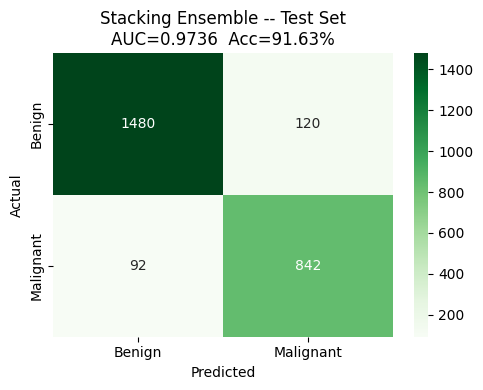

stacking_test_confusion.png saved


In [11]:
# ── Cell: Final Test Set Accuracy & AUC ─────────────────────────────────────
# Uses the true test labels saved by the base model notebooks.
# All 4 base models use the same test CSV (shuffle=False), so test labels match.

from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve, classification_report, confusion_matrix
import seaborn as sns

# Load true test labels (any model's file works -- they all share the same test CSV)
# Pull the shared true test labels from the dictionary we loaded earlier
true_test_labels = test_labels_dict[model_names[0]]
print(f'Test labels loaded from: {model_names[0]}  (n={len(true_test_labels)})')

if true_test_labels is None:
    print('ERROR: No test label file found in NPY_DIR. Cannot compute test accuracy.')
else:
    ens_preds = (test_final_probs >= 0.5).astype(int)

    test_acc = accuracy_score(true_test_labels, ens_preds)
    test_auc = roc_auc_score(true_test_labels, test_final_probs)

    print()
    print('=' * 58)
    print('   STACKING ENSEMBLE -- FINAL TEST SET RESULTS')
    print('=' * 58)
    print(f'   Test AUC      : {test_auc:.4f}')
    print(f'   Test Accuracy : {test_acc * 100:.2f}%')
    print('=' * 58)
    print()
    print('Classification Report (Test Set):')
    print(classification_report(
        true_test_labels, ens_preds,
        target_names=['Benign (0)', 'Malignant (1)'], digits=4
    ))

    # Confusion matrix
    fig, ax = plt.subplots(figsize=(5, 4))
    cm = confusion_matrix(true_test_labels, ens_preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', ax=ax,
                xticklabels=['Benign', 'Malignant'],
                yticklabels=['Benign', 'Malignant'])
    ax.set_title(f'Stacking Ensemble -- Test Set\nAUC={test_auc:.4f}  Acc={test_acc*100:.2f}%')
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    plt.tight_layout()
    plt.savefig('/kaggle/working/stacking_test_confusion.png', dpi=150, bbox_inches='tight')
    plt.show()
    print('stacking_test_confusion.png saved')


In [12]:
# ── Cell 9: Submission CSV ─────────────────────────────────────────────────
# Uses binary_test.csv (from data-preparation) to get image IDs

INPUT_CSV_DIR  = '/kaggle/working'
TEST_CSV_PATH  = os.path.join(INPUT_CSV_DIR, 'binary_test.csv')

if os.path.exists(TEST_CSV_PATH):
    test_df = pd.read_csv(TEST_CSV_PATH)
    if len(test_df) != len(test_final_probs):
        print(f'WARNING: CSV has {len(test_df)} rows but predictions have {len(test_final_probs)}')
        print('Saving raw probabilities only.')
    else:
        submission = pd.DataFrame({
            'image':  test_df['image'],
            'target': test_final_probs,
        })
        sub_path = '/kaggle/working/stacking_submission.csv'
        submission.to_csv(sub_path, index=False)
        print(f'Submission saved -> {sub_path}')
        print(submission.head(10))
else:
    print(f'Test CSV not found at {TEST_CSV_PATH}')
    print('Raw probabilities saved in stacking_test_probs.npy')


Test CSV not found at /kaggle/working/binary_test.csv
Raw probabilities saved in stacking_test_probs.npy


In [13]:
# ── Cell 10: Final Summary ─────────────────────────────────────────────────
print('=' * 60)
print('  FINAL SUMMARY')
print('=' * 60)
print(f'  {"Model":20s}  {"Val AUC":>10}  {"Val N":>8}')
print(f'  {"-"*42}')
for m in model_names:
    print(f'  {m:20s}  {val_aucs[m]:>10.4f}  {len(val_labels_dict[m]):>8}')
print(f'  {"-"*42}')
if USE_META_LEARNER:
    label = f'Meta-Learner ({best_group})'
    print(f'  Val AUC (meta, shared split): {val_meta_auc:.4f}')
    print(f'  Models in meta-learner:        {best_group}')
    remaining = [m for m in model_names if m not in best_group]
    if remaining:
        print(f'  Models blended (AUC-weight):   {remaining}')
else:
    print('  Strategy: AUC-weighted average (no common split found)')
print('=' * 60)
print('\nOutput files:')
print('  stacking_test_probs.npy')
if USE_META_LEARNER:
    print('  lr_stacker.pkl')
print('  stacking_roc_curves.png')
if USE_META_LEARNER:
    print('  stacking_cm.png')

  FINAL SUMMARY
  Model                    Val AUC     Val N
  ------------------------------------------
  densenet121               0.9479      2533
  convnext                  0.9623      2533
  efficientnetv2s           0.9698      2533
  swintiny                  0.9596      2533
  resnet200d                0.9631      2533
  ------------------------------------------
  Val AUC (meta, shared split): 0.9931
  Models in meta-learner:        ['densenet121', 'convnext', 'efficientnetv2s', 'swintiny', 'resnet200d']

Output files:
  stacking_test_probs.npy
  stacking_roc_curves.png
  stacking_cm.png
